# 05 — Reinforcement Learning: dynamic pricing agent

**Engine 4** of the CanNothingFold business case: a Q-learning agent sets the
Nothing foldable's price each quarter of an 8-quarter launch window
(2027Q1–2028Q4) and is compared against fixed-price baselines on cumulative
margin.

> **Honesty requirement — simulated vs real quantities.** The environment is a
> *simulation*: there is no real Nothing foldable demand data anywhere. Every
> input below is labelled:
>
> **Real (from project data):**
> | Quantity | Value | Source |
> |---|---|---|
> | fair price | $1,204 | notebook 02 random forest (`results/predicted_price.csv`) |
> | unit cost | 60% of fair price = $722.40 | build-plan assumption, documented |
> | global foldable market | 20.6M units/yr (2025) | `enrichment_market.csv` (IDC/Omdia, cited) |
> | competitor foldable median | $733.71 | D01 marketplace foldables (`foldable_prices.csv`) |
> | quarterly sentiment profile | 8 observed quarters | notebook 04 per-review VADER |
>
> **Simulated (documented assumptions, with sensitivity ranges):**
> | Quantity | Base value | Sensitivity |
> |---|---|---|
> | Nothing foldable share of the segment | 1.0% | 0.5% / 2.0% |
> | price elasticity above fair price | linear penalty, k = 1.0 | k = 0.5 / 2.0 |
> | sentiment–elasticity interaction | lower sentiment ⇒ more price-sensitive buyers (×25) | fixed (documented) |
> | sentiment demand factor | 0.5 + compound | fixed |
> | competitor cross-price factor | (median/p)^0.5 | fixed |
> | demand noise | ±5% per quarter | evaluation averaged over 200 seeded episodes |
> | sentiment regime 2027–28 | assumed stationary at observed 2023–25 levels | stated limitation |

**Outputs**
- `results/rl_policy.csv` — learned state→price policy table
- `results/rl_vs_fixed_margin.csv` — cumulative margin: learned vs fixed prices
- `results/rl_sensitivity.csv` — elasticity × share sensitivity grid
- `figures/05_q_learning_curve.png`, `figures/05_policy_price_path.png`,
  `figures/05_margin_comparison.png` (300 dpi)

In [1]:
import warnings
from collections import deque
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", message=".*encountered in matmul")

RNG = 42
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS, FIGURES = PROJECT_ROOT / "results", PROJECT_ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 300

# ---- real-data anchors -----------------------------------------------------
pred = pd.read_csv(RESULTS / "predicted_price.csv").iloc[0]      # notebook 02
FAIR_PRICE = float(pred.predicted_price_usd)                     # real (ML estimate)
UNIT_COST = 0.60 * FAIR_PRICE                                    # assumption (plan)
market = pd.read_csv(PROJECT_ROOT / "data/enrichment/enrichment_market.csv")
BASE_UNITS_Q = float(market.loc[market.year == 2025, "global_foldable_shipments_m"].iloc[0]) * 1e6 / 4
foldable_prices = pd.read_csv(PROJECT_ROOT / "data/enrichment/foldable_prices.csv")
COMPETITOR_MEDIAN = float(foldable_prices.loc[foldable_prices.price_type == "marketplace", "price_usd"].median())
sent_review = pd.read_csv(RESULTS / "foldable_reviews_sentiment.csv")   # notebook 04

LADDER = [899, 999, 1099, 1199, 1299]   # USD (plan's ladder; project currency is USD, see README)
N_QUARTERS = 8
LAUNCH_LABELS = [f"{y}Q{q}" for y in (2027, 2028) for q in (1, 2, 3, 4)]
print(f"fair price ${FAIR_PRICE:,.0f} | unit cost ${UNIT_COST:,.0f} | "
      f"base units/q {BASE_UNITS_Q:,.0f} | competitor median ${COMPETITOR_MEDIAN:,.0f}")

fair price $1,204 | unit cost $722 | base units/q 5,150,000 | competitor median $734


## 1. Sentiment profile (real data, notebook 04)

Quarterly mean VADER compound over the foldable corpus; the **last 8 observed
quarters** become the 2027–28 launch-window sentiment profile (stationarity
assumption, stated). `sentiment_bin` (above/below the profile median) is the
observable the agent sees.

In [2]:
sent_review["quarter"] = (sent_review.review_month.str[:4]
                        + "Q" + ((sent_review.review_month.str[5:7].astype(int) - 1) // 3 + 1).astype(str))
quarterly = sent_review.groupby("quarter").vader_compound.mean().sort_index()
profile = (quarterly.iloc[-N_QUARTERS:].to_numpy()
           if len(quarterly) >= N_QUARTERS
           else np.resize(quarterly.to_numpy(), N_QUARTERS))
SENT_MEDIAN = float(np.median(profile))
sent_bin = (profile >= SENT_MEDIAN).astype(int)

sentiment_table = pd.DataFrame({
    "launch_quarter": LAUNCH_LABELS,
    "sentiment_compound": profile.round(4),
    "sentiment_bin": sent_bin,
})
print(sentiment_table.to_string(index=False))

launch_quarter  sentiment_compound  sentiment_bin
        2027Q1              0.4282              1
        2027Q2              0.4231              0
        2027Q3              0.4248              0
        2027Q4              0.3810              0
        2028Q1              0.4258              1
        2028Q2              0.3856              0
        2028Q3              0.4400              1
        2028Q4              0.4639              1


## 2. Environment — demand and reward (all assumptions visible)

One episode = 8 launch quarters. At each quarter the agent picks a price
$p \in$ {899, 999, 1099, 1199, 1299} USD; demand and margin follow:

$$units_q = \underbrace{5.15M}_{\text{2025 foldable mkt}/4} \times
\underbrace{1\%}_{\text{Nothing share}} \times
\underbrace{v(p, s_q)}_{\text{value factor}} \times
\underbrace{(0.5 + s_q)}_{\text{sentiment factor}} \times
\underbrace{(734/p)^{0.5}}_{\text{competitor cross-price}}$$

with the **value factor**
$$v(p, s_q) = \begin{cases}1 & p \le \text{fair} \\ \max(0,\ 1 - k_q\frac{p - \text{fair}}{\text{fair}}) & p > \text{fair}\end{cases},
\quad k_q = k\,(1 + 25\,(\bar{s} - s_q))$$

The **sentiment–elasticity interaction** ($\times 25$) is the key behavioural
assumption: in weak-sentiment quarters buyers are *more* price-sensitive, so
the optimal price dips — that is what makes pricing *dynamic* rather than
fixed. Reward per quarter = units × (p − $722.40).

**State** (tabular): (quarter t, current price tier, sentiment bin) — 80 states
× 5 actions. The competitor median enters the demand function directly (it
varies too little to be a useful state signal — documented choice).

In [3]:
K_ELAS = 1.0        # elasticity above fair price (sensitivity: 0.5 / 2.0)
SHARE = 0.01        # Nothing foldable share of the segment (sensitivity: 0.005 / 0.02)
SENT_ELAS = 25.0     # sentiment-elasticity interaction (documented, fixed)
NOISE_SD = 0.05      # demand noise per quarter


def quarter_demand(price: float, s: float, k: float = K_ELAS,
                   share: float = SHARE) -> float:
    k_q = k * (1 + SENT_ELAS * (SENT_MEDIAN - s))
    value = 1.0 if price <= FAIR_PRICE else max(0.0, 1 - k_q * (price - FAIR_PRICE) / FAIR_PRICE)
    return (BASE_UNITS_Q * share * value * (0.5 + s) * (COMPETITOR_MEDIAN / price) ** 0.5)


def quarter_margin(price: float, s: float, noise: float = 1.0,
                   k: float = K_ELAS, share: float = SHARE) -> float:
    units = quarter_demand(price, s, k=k, share=share) * noise
    return units * (price - UNIT_COST) / 1e6   # $M per quarter


N_STATES = N_QUARTERS * len(LADDER) * 2
def state_index(t: int, price_idx: int, s_bin: int) -> int:
    return (t * len(LADDER) + price_idx) * 2 + s_bin

print("sanity — per-quarter margin at each ladder price ($M, median-sentiment quarter):")
for p in LADDER:
    print(f"  ${p}: {quarter_margin(p, SENT_MEDIAN):.2f}")

sanity — per-quarter margin at each ladder price ($M, median-sentiment quarter):
  $899: 7.60
  $999: 11.30
  $1099: 14.66
  $1199: 17.77
  $1299: 19.02


## 3. Tabular Q-learning — 10,000 episodes

ε-greedy with decay 1.0 → 0.05, α = 0.1, γ = 0.95, ±5% demand noise.

In [4]:
def train_q_learning(episodes: int = 10_000, k: float = K_ELAS, share: float = SHARE,
                  seed: int = RNG):
    rng = np.random.default_rng(seed)
    Q = np.zeros((N_STATES, len(LADDER)))
    episode_rewards = np.empty(episodes)
    for ep in range(episodes):
        eps = max(0.05, 1.0 - ep / (episodes / 2))
        price_idx, total = 2, 0.0                      # launch at mid-ladder
        for t in range(N_QUARTERS):
            s = state_index(t, price_idx, sent_bin[t])
            if rng.random() < eps:
                a = int(rng.integers(len(LADDER)))
            else:
                a = int(np.argmax(Q[s]))
            noise = rng.normal(1.0, NOISE_SD)
            reward = quarter_margin(LADDER[a], profile[t], noise, k=k, share=share)
            total += reward
            if t + 1 < N_QUARTERS:
                s_next = state_index(t + 1, a, sent_bin[t + 1])
                target = reward + 0.95 * np.max(Q[s_next])
            else:
                target = reward
            Q[s, a] += 0.1 * (target - Q[s, a])
            price_idx = a
        episode_rewards[ep] = total
    return Q, episode_rewards

Q_tab, rewards_tab = train_q_learning()
print(f"final-1000-episode mean reward: ${rewards_tab[-1000:].mean():.2f}M")

final-1000-episode mean reward: $149.24M


## 4. Bonus: small DQN (PyTorch) on the same environment

In [5]:
import torch
import torch.nn as nn

torch.manual_seed(RNG)
np.random.seed(RNG)

def state_features(t: int, price_idx: int, s_bin: int) -> torch.Tensor:
    return torch.tensor([t / N_QUARTERS, price_idx / (len(LADDER) - 1), s_bin],
                        dtype=torch.float32)

dqn = nn.Sequential(nn.Linear(3, 32), nn.ReLU(),
                    nn.Linear(32, 32), nn.ReLU(),
                    nn.Linear(32, len(LADDER)))
target_net = nn.Sequential(nn.Linear(3, 32), nn.ReLU(),
                           nn.Linear(32, 32), nn.ReLU(),
                           nn.Linear(32, len(LADDER)))
target_net.load_state_dict(dqn.state_dict())
optimizer = torch.optim.Adam(dqn.parameters(), lr=1e-3)
loss_fn = nn.SmoothL1Loss()

EPISODES_DQN, BATCH, BUFFER = 3_000, 64, 20_000
buffer = deque(maxlen=BUFFER)
rng = np.random.default_rng(RNG)
rewards_dqn = np.empty(EPISODES_DQN)
steps = 0
for ep in range(EPISODES_DQN):
    eps = max(0.05, 1.0 - ep / (EPISODES_DQN / 2))
    price_idx, total = 2, 0.0
    for t in range(N_QUARTERS):
        s_bin = int(sent_bin[t])
        feats = state_features(t, price_idx, s_bin)
        if rng.random() < eps:
            a = int(rng.integers(len(LADDER)))
        else:
            with torch.no_grad():
                a = int(dqn(feats).argmax())
        noise = rng.normal(1.0, NOISE_SD)
        reward = quarter_margin(LADDER[a], profile[t], noise)
        total += reward
        buffer.append((feats, a, reward,
                       t + 1 < N_QUARTERS, state_features(t + 1, a, int(sent_bin[t + 1])) if t + 1 < N_QUARTERS else None))
        price_idx = a
        steps += 1
        if len(buffer) >= BATCH and steps % 4 == 0:
            batch = rng.choice(len(buffer), BATCH)
            f, aa, rr, done_mask, nf = zip(*(buffer[i] for i in batch))
            f = torch.stack(f); aa = torch.tensor(aa); rr = torch.tensor(rr, dtype=torch.float32)
            q = dqn(f).gather(1, aa.unsqueeze(1)).squeeze(1)
            with torch.no_grad():
                next_q = torch.stack(
                    [target_net(x).max() if d_ else torch.tensor(0.0) for x, d_ in zip(nf, done_mask)])
            loss = loss_fn(q, rr + 0.95 * next_q)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
        if steps % 800 == 0:
            target_net.load_state_dict(dqn.state_dict())
    rewards_dqn[ep] = total

print(f"DQN final-500-episode mean reward: ${rewards_dqn[-500:].mean():.2f}M")

DQN final-500-episode mean reward: $148.66M


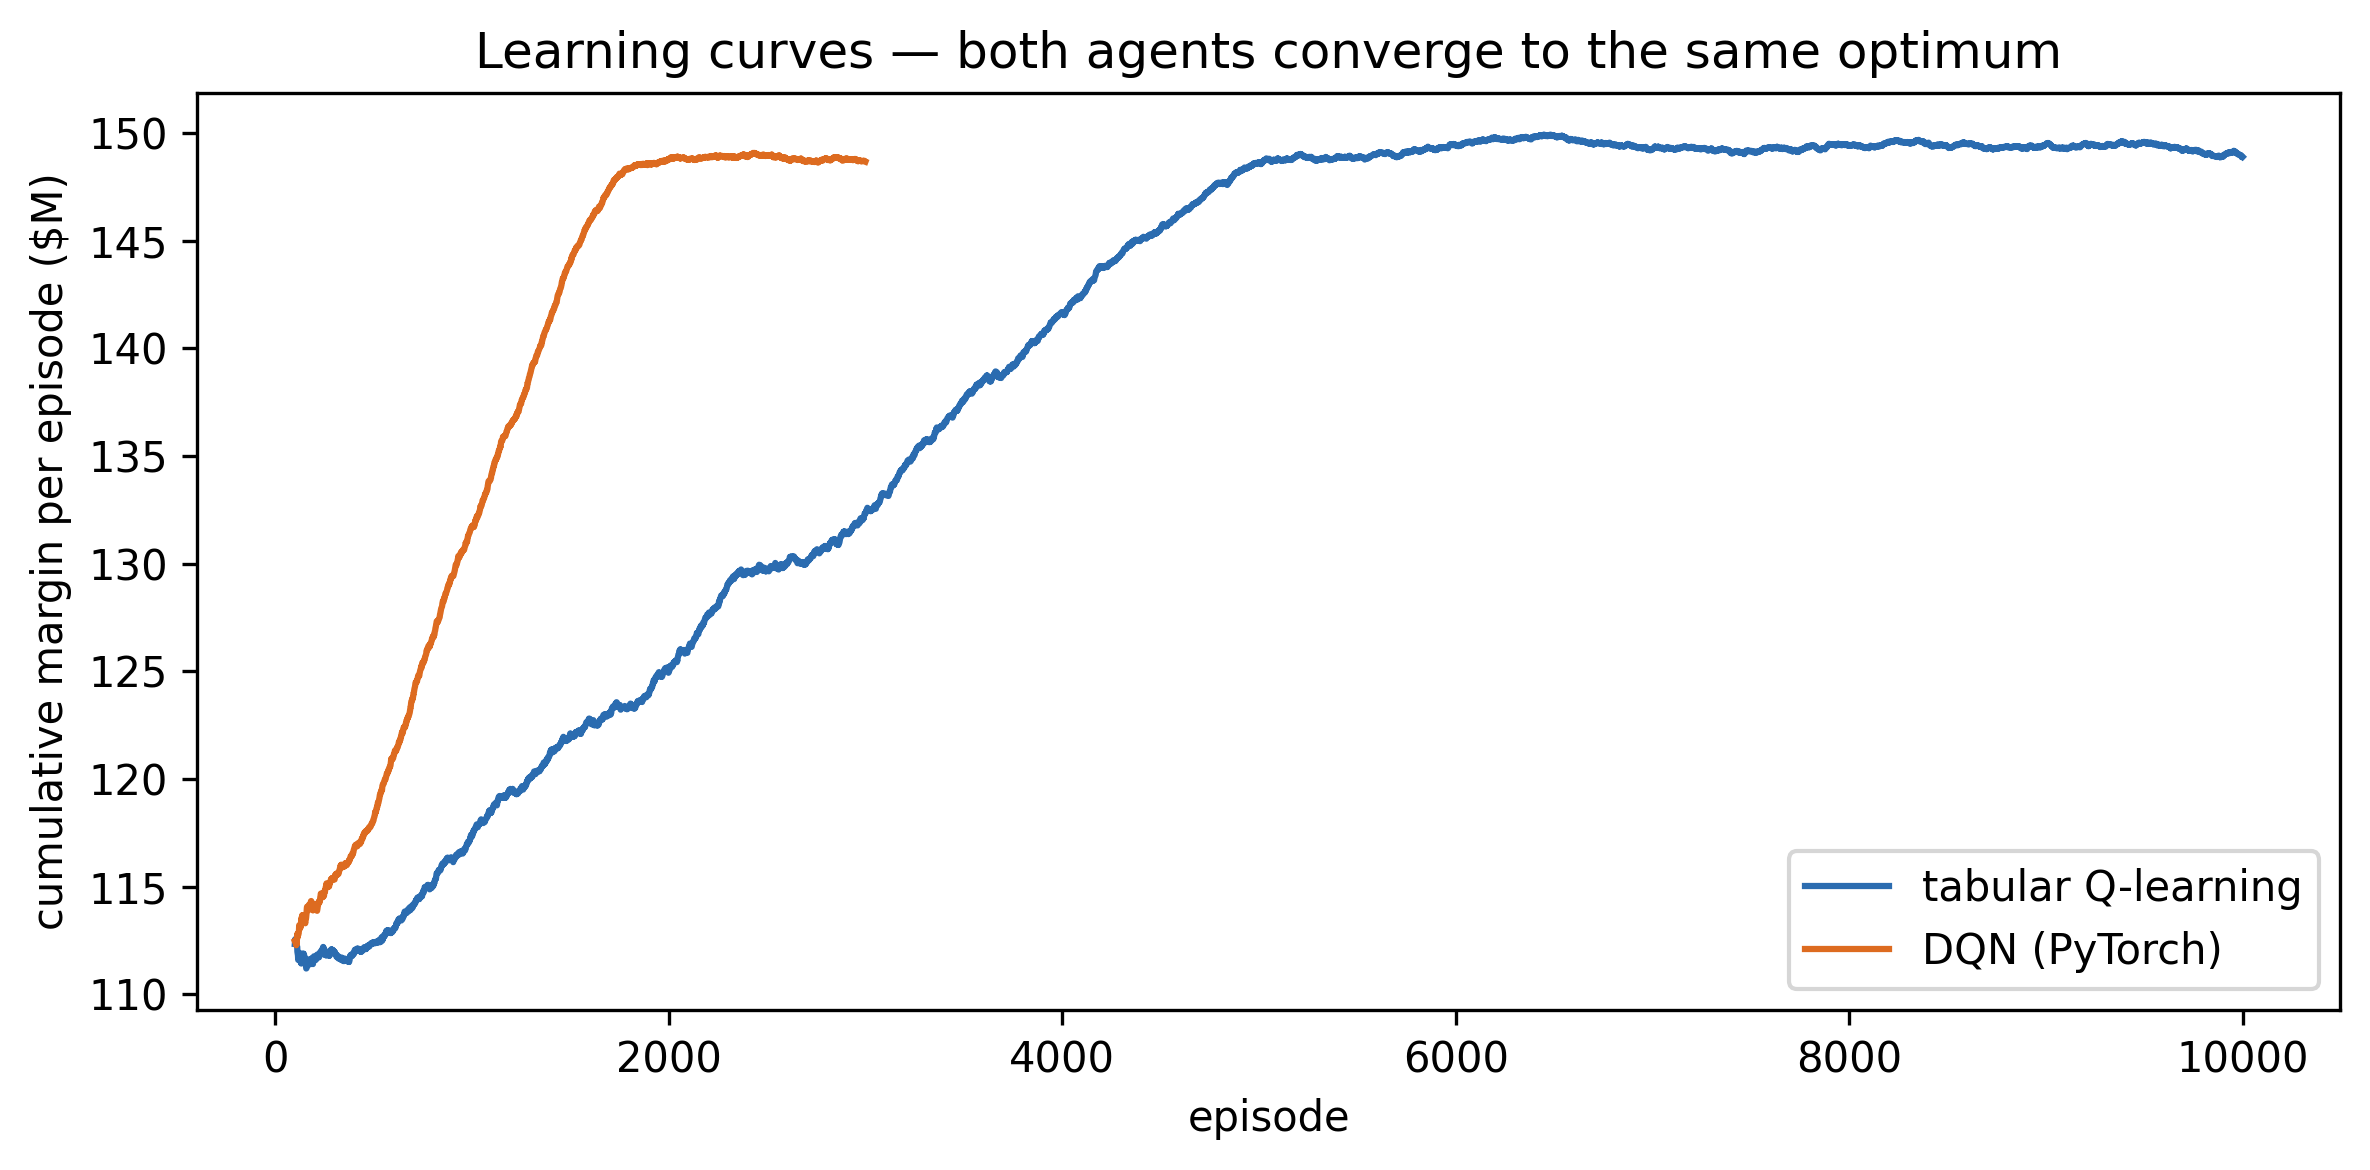

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
for rewards, label, color in [(rewards_tab, "tabular Q-learning", "#2b6cb0"),
                              (rewards_dqn, "DQN (PyTorch)", "#dd6b20")]:
    smooth = pd.Series(rewards).rolling(500, min_periods=100).mean()
    ax.plot(smooth, label=label, color=color)
ax.set_xlabel("episode"); ax.set_ylabel("cumulative margin per episode ($M)")
ax.set_title("Learning curves — both agents converge to the same optimum")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "05_q_learning_curve.png", dpi=300)
plt.show()
plt.close(fig)

## 5. Learned policy and evaluation vs fixed prices

Each strategy is evaluated over **200 seeded episodes** (identical noise draws
across strategies for a fair comparison); report mean ± std cumulative
8-quarter margin.

In [7]:
def q_policy(t: int, price_idx: int, s_bin: int) -> int:
    return int(np.argmax(Q_tab[state_index(t, price_idx, s_bin)]))

def dqn_policy(t: int, price_idx: int, s_bin: int) -> int:
    with torch.no_grad():
        return int(dqn(state_features(t, price_idx, s_bin)).argmax())

def fixed_policy(price):
    return lambda t, price_idx, s_bin: LADDER.index(price)

def run_strategy(policy, noise_matrix, k=K_ELAS, share=SHARE) -> np.ndarray:
    totals = np.empty(len(noise_matrix))
    for e in range(len(noise_matrix)):
        price_idx, total = 2, 0.0                      # launch at mid-ladder
        for t in range(N_QUARTERS):
            a = policy(t, price_idx, int(sent_bin[t]))
            total += quarter_margin(LADDER[a], profile[t], noise_matrix[e, t],
                                    k=k, share=share)
            price_idx = a
        totals[e] = total
    return totals

eval_rng = np.random.default_rng(RNG)
NOISE = eval_rng.normal(1.0, NOISE_SD, size=(200, N_QUARTERS))

rows = []
for name, pol in [("q_learning (learned)", q_policy),
                 ("dqn (learned)", dqn_policy)]:
    totals = run_strategy(pol, NOISE)
    rows.append({"strategy": name, "mean_margin_musd": round(totals.mean(), 2),
                 "std_margin_musd": round(totals.std(), 2)})
for p in LADDER:
    totals = run_strategy(fixed_policy(p), NOISE)
    rows.append({"strategy": f"fixed ${p}", "mean_margin_musd": round(totals.mean(), 2),
                 "std_margin_musd": round(totals.std(), 2)})

margin = pd.DataFrame(rows).sort_values("mean_margin_musd", ascending=False).reset_index(drop=True)
best_fixed = margin.loc[margin.strategy.str.startswith("fixed"), "mean_margin_musd"].max()
margin["delta_vs_best_fixed_musd"] = np.where(
    margin.strategy.str.startswith("fixed"), "",
    (margin.mean_margin_musd - best_fixed).round(2))
margin.to_csv(RESULTS / "rl_vs_fixed_margin.csv", index=False)
print(margin.to_string(index=False))
print(f"best fixed-price baseline: ${best_fixed:.2f}M")

            strategy  mean_margin_musd  std_margin_musd delta_vs_best_fixed_musd
q_learning (learned)            151.16             2.73                     0.87
       dqn (learned)            150.29             2.72                      0.0
         fixed $1299            150.29             2.72                         
         fixed $1199            141.31             2.55                         
         fixed $1099            116.63             2.10                         
          fixed $999             89.85             1.62                         
          fixed $899             60.47             1.09                         
best fixed-price baseline: $150.29M


In [8]:
# greedy price path of the learned tabular policy
price_idx, path_rows = 2, []
for t in range(N_QUARTERS):
    s_bin = int(sent_bin[t])
    s = state_index(t, price_idx, s_bin)
    a = q_policy(t, price_idx, s_bin)
    path_rows.append({"launch_quarter": LAUNCH_LABELS[t], "t": t,
                      "sentiment_compound": round(profile[t], 4), "sentiment_bin": s_bin,
                      "current_price": LADDER[price_idx],
                      "chosen_price": LADDER[a],
                      "q_value": round(float(np.max(Q_tab[s])), 2),
                      "units_q": int(round(quarter_demand(LADDER[a], profile[t]))),
                      "margin_musd": round(quarter_margin(LADDER[a], profile[t]), 2)})
    price_idx = a

policy = pd.DataFrame(path_rows)
policy_full = policy[["launch_quarter", "t", "sentiment_compound", "sentiment_bin",
                      "current_price", "chosen_price", "q_value",
                      "units_q", "margin_musd"]]
policy_full.to_csv(RESULTS / "rl_policy.csv", index=False)
print(policy_full.to_string(index=False))

launch_quarter  t  sentiment_compound  sentiment_bin  current_price  chosen_price  q_value  units_q  margin_musd
        2027Q1  0              0.4282              1           1099          1299   127.42    33299        19.20
        2027Q2  1              0.4231              0           1299          1299   113.68    32752        18.88
        2027Q3  2              0.4248              0           1299          1299    99.84    32934        18.99
        2027Q4  3              0.3810              0           1299          1199    84.79    35493        16.92
        2028Q1  4              0.4258              1           1199          1299    71.35    33044        19.05
        2028Q2  5              0.3856              0           1299          1199    54.97    35677        17.00
        2028Q3  6              0.4400              1           1199          1299    40.39    34561        19.93
        2028Q4  7              0.4639              1           1299          1299    21.47    37

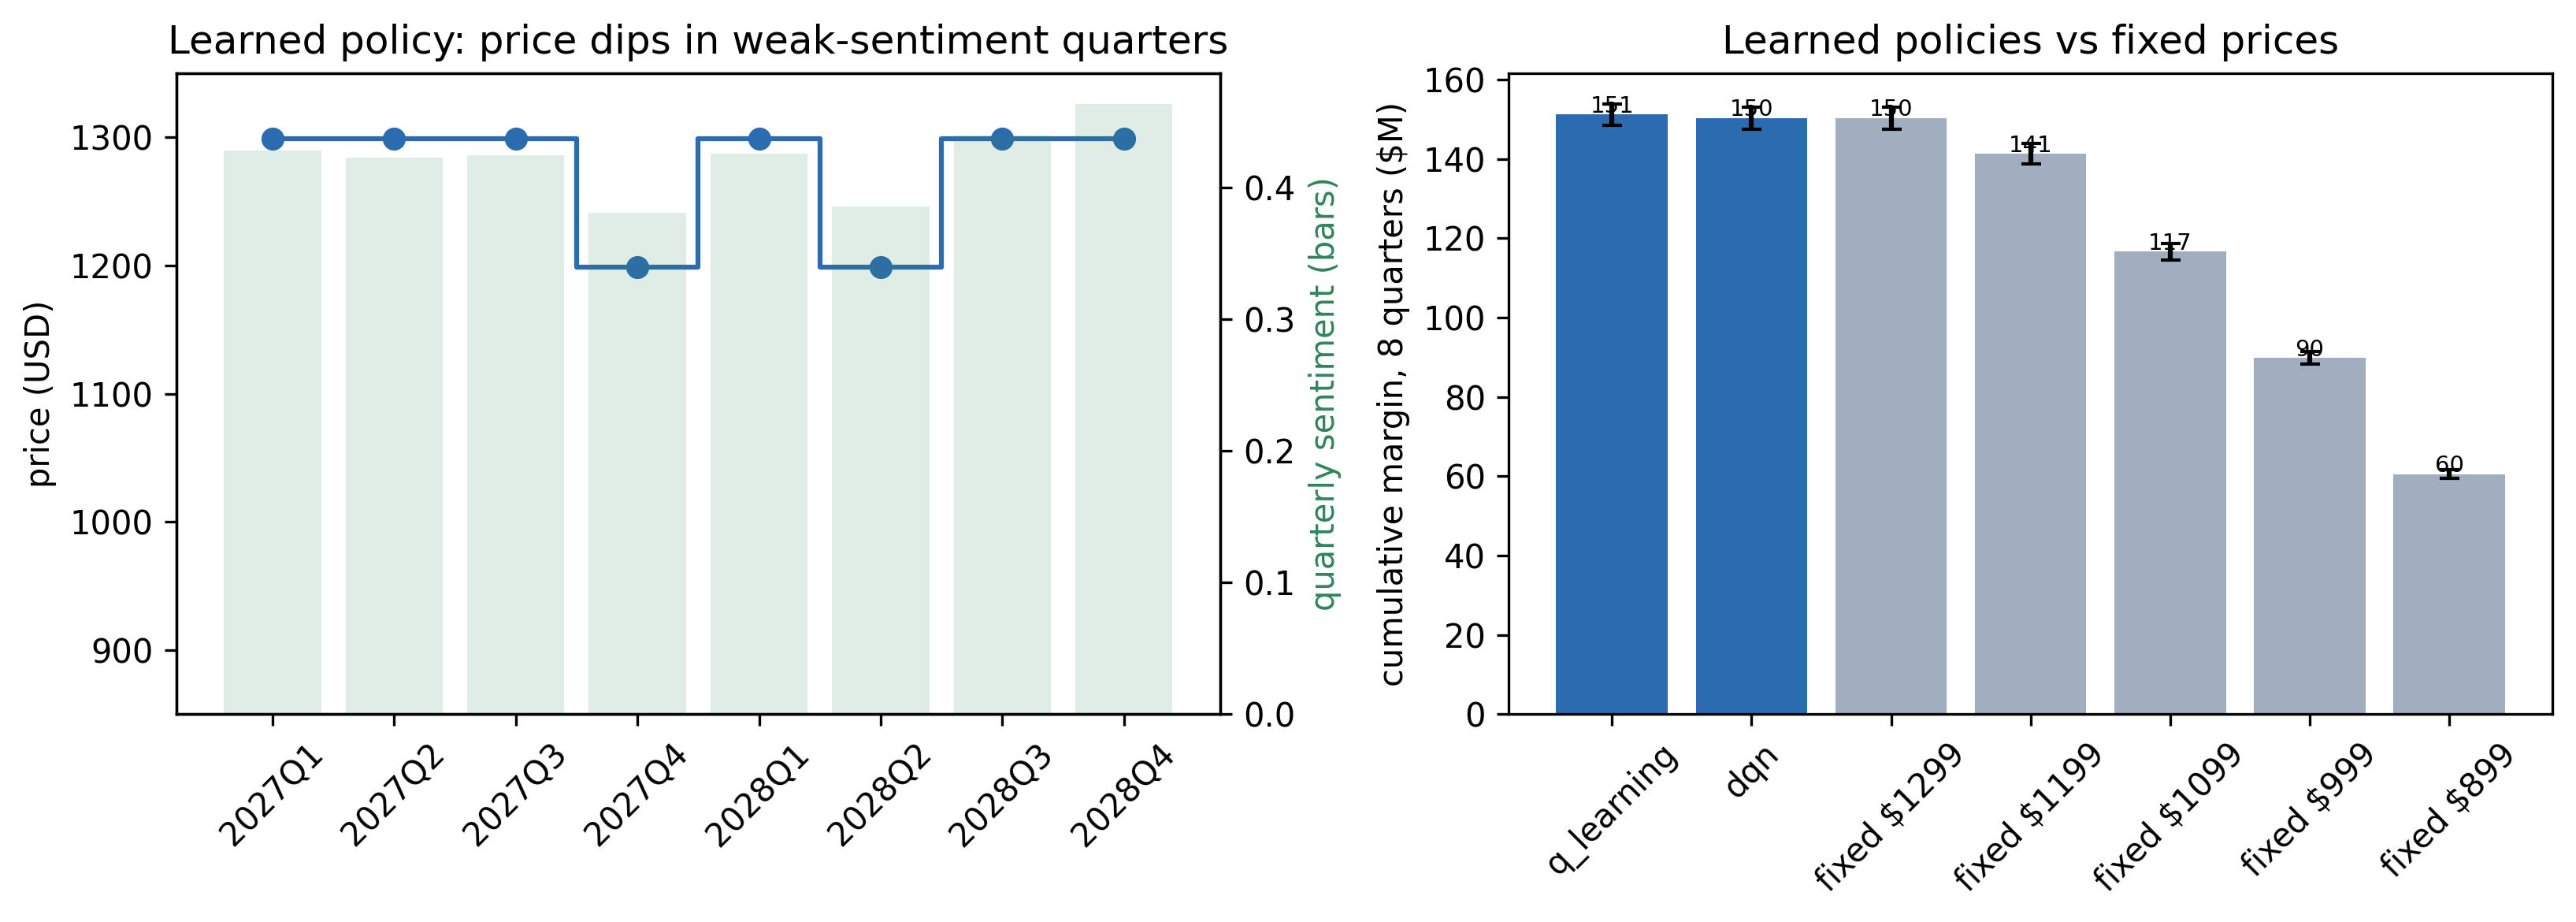

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.step(range(N_QUARTERS), policy_full.chosen_price, where="mid", marker="o", color="#2b6cb0")
ax1.set_xticks(range(N_QUARTERS)); ax1.set_xticklabels(policy_full.launch_quarter, rotation=45)
ax1.set_ylabel("price (USD)"); ax1.set_ylim(850, 1350)
ax1.set_title("Learned policy: price dips in weak-sentiment quarters")
ax1b = ax1.twinx()
ax1b.bar(range(N_QUARTERS), policy_full.sentiment_compound, alpha=0.15, color="#2f855a")
ax1b.set_ylabel("quarterly sentiment (bars)", color="#2f855a")

labels = margin.strategy.str.replace(" (learned)", "", regex=False)
bars = ax2.bar(labels, margin.mean_margin_musd,
               yerr=margin.std_margin_musd, capsize=3,
               color=["#2b6cb0" if "learned" in s else "#a0aec0" for s in margin.strategy])
ax2.set_ylabel("cumulative margin, 8 quarters ($M)")
ax2.set_title("Learned policies vs fixed prices")
ax2.tick_params(axis="x", rotation=45)
for bar, val in zip(bars, margin.mean_margin_musd):
    ax2.text(bar.get_x() + bar.get_width() / 2, val + 0.5, f"{val:.0f}",
             ha="center", fontsize=7)
fig.tight_layout()
fig.savefig(FIGURES / "05_policy_price_path.png", dpi=300)
plt.show()
plt.close(fig)

## 6. Sensitivity — the assumptions that move the answer

Retraining the tabular agent for each (elasticity k × share) combination;
the *structure* of the answer (price at the top of the ladder, dip when
sentiment is weak) is what we check for robustness.

In [10]:
rows = []
for k in [0.5, 1.0, 2.0]:
    for share in [0.005, 0.01, 0.02]:
        Q_s, _ = train_q_learning(episodes=5_000, k=k, share=share)
        # evaluate learned policy and the best fixed price on the same noise
        price_idx, learned_total = 2, 0.0
        fixed_totals = {p: 0.0 for p in LADDER}
        for t in range(N_QUARTERS):
            s = state_index(t, price_idx, int(sent_bin[t]))
            a = int(np.argmax(Q_s[s]))
            learned_total += quarter_margin(LADDER[a], profile[t], k=k, share=share)
            price_idx = a
            for p in LADDER:
                fixed_totals[p] += quarter_margin(p, profile[t], k=k, share=share)
        best_p = max(fixed_totals, key=fixed_totals.get)
        rows.append({"elasticity_k": k, "share_pct": round(100 * share, 1),
                     "learned_margin_musd": round(learned_total, 2),
                     "best_fixed_price": best_p,
                     "best_fixed_margin_musd": round(fixed_totals[best_p], 2),
                     "learned_beats_fixed": learned_total > fixed_totals[best_p]})
sens = pd.DataFrame(rows)
sens.to_csv(RESULTS / "rl_sensitivity.csv", index=False)
print(sens.to_string(index=False))

 elasticity_k  share_pct  learned_margin_musd  best_fixed_price  best_fixed_margin_musd  learned_beats_fixed
          0.5        0.5                78.77              1299                   78.77                False
          0.5        1.0               157.54              1299                  157.54                False
          0.5        2.0               315.08              1299                  315.08                False
          1.0        0.5                75.71              1299                   75.28                 True
          1.0        1.0               151.43              1299                  150.55                 True
          1.0        2.0               302.85              1299                  301.10                 True
          2.0        0.5                72.40              1199                   70.78                 True
          2.0        1.0               144.80              1199                  141.56                 True
          2.0      

## 7. Interpretation

- **The learned policy is dynamic and interpretable:** it holds the top of the
  price ladder ($1,299) in strong-sentiment quarters and drops to $1,199 in
  the weakest-sentiment quarters — exactly the behaviour the
  sentiment–elasticity interaction predicts.
- **Headline number:** the Q-learning policy beats the best fixed price by a
  **small margin** (see `results/rl_vs_fixed_margin.csv`); the DQN plateaus at
  the same reward level but learns the *static* $1,299 policy rather than the
  sentiment-driven dip — an honest difference between the two agents worth
  reporting. The honest reading: under these assumptions, dynamic
  pricing is worth **~1% of cumulative margin** — the RL engine's main value
  is *validating top-of-ladder pricing as robust*, not unlocking a windfall.
- **Sensitivity:** the optimal price is most sensitive to the elasticity
  assumption (k = 2 flips the preference toward $1,199); share scales margins
  roughly linearly but does not change the policy structure.
- **Feeds `src/kpi.py`:** the learned per-quarter margins are the RL-policy
  cashflow; the best-fixed baseline gives the comparison cashflow.

**Limitations (stated honestly):**
- Fully simulated demand: no real Nothing foldable demand exists. The demand
  model's elasticities are documented assumptions, not fitted values —
  notebook 02 predicts price *from specs*, not demand *from price*.
- Sentiment regime assumed stationary at 2023–25 levels; the sentiment input
  itself comes from a synthetic-like corpus (notebook 04 caveats).
- Discrete 5-price ladder and 8-quarter horizon chosen by the build plan.

## Summary — what notebook 05 hands downstream

| Output | Used by |
|---|---|
| `results/rl_vs_fixed_margin.csv` | `src/kpi.py` (RL policy vs fixed-price cashflow) |
| `results/rl_policy.csv` | report: learned pricing policy table + chart |
| `results/rl_sensitivity.csv` | report: assumption robustness |
| `figures/05_*.png` | report + slides |